# Genes Toxoplasma needs under mouse immune pressure


# Which Toxoplasma genes are specifically important under mouse immune pressure?

Einar, 2026-11-04. A deliberately concrete question, chosen as an easier first target than host-facing, and one where we already know part of the answer, so the method can be *scored* rather than admired.

**The biology.** A mouse macrophage activated by interferon gamma (IFN-gamma) attacks the parasitophorous vacuole with the IRG (immunity-related GTPase) system: IRGB10 and friends coat the vacuolar membrane, break it, and the exposed parasite is killed. Mice have a large IRG family; humans have essentially none (humans use a different, GBP- and ubiquitin-centred route). Toxoplasma defends the vacuole with a small set of secreted effectors -- the ROP5/ROP18/ROP17/GRA7 pseudokinase complex phosphorylates and inactivates IRGs, and GRA12 protects the vacuole by a separate route. So the genes a parasite needs *only* when the mouse cell is activated should be dominated by vacuole-facing secreted proteins, and that is a prediction we can check.

**The question in data terms.** Which genes cost the parasite fitness when the same mouse macrophages are IFN-gamma-activated, over and above what they cost in the same cells unactivated?

## 1 · The three fitness screens we have, and why they cannot be mixed

ParaScape carries three families of CRISPR fitness columns in `parascape/data/nodes.parquet`:

* `fit_invitro_hff` -- Sidik 2016 (PMID 27594426), human foreskin fibroblasts, **absolute** competitive growth over 3 passages. Negative = the gene is needed to grow.

* `fit_naive_bmdm`, `fit_ifng` -- Wang 2020 (PMID 33067458), **mouse** bone-marrow-derived macrophages, naive and IFN-gamma-activated. Reported relative to a control condition, so general growth requirement has already been normalised out.

* `fit_invivo_*` -- Giuliano 2024 (PMID 38977907), six mouse tissues. These values are a **product of differential fitness and significance**, not an effect size: GRA12 reads -41.56, which is not a log2 fold change of anything. They are usable as a *ranking statistic only*.

Einar found this trap before the analysis started; the next cell re-verifies it from the data rather than taking it on trust. The test is the 158 cytosolic ribosomal proteins: every parasite needs its ribosome, so in an absolute growth screen they must sit far below the bulk of genes, and in a growth-normalised screen they must sit on top of it.

In [1]:
import json, hashlib
from pathlib import Path
import numpy as np, pandas as pd
from scipy import stats

OUT = Path('results/mouse_immune_dependence_2026_11_04'); OUT.mkdir(parents=True, exist_ok=True)
nodes = pd.read_parquet('parascape/data/nodes.parquet').set_index('gene_id')
values = pd.read_parquet('results/information_map_v0_2026_11_04/values.parquet')
print(len(nodes), 'genes in nodes.parquet;', len(values), 'rows in the information map')

product = nodes['product'].fillna('')
ribosomal = product.str.contains('ribosomal protein', case=False)
print(int(ribosomal.sum()), 'genes whose product name is a ribosomal protein')

scale = []
for col in ('fit_invitro_hff', 'fit_naive_bmdm', 'fit_ifng', 'fit_invivo_brain'):
    scale.append(dict(column=col, genes_measured=int(nodes[col].notna().sum()),
                      ribosomal_median=nodes.loc[ribosomal, col].median(),
                      all_genes_median=nodes[col].median(),
                      min=nodes[col].min(), max=nodes[col].max()))
scale = pd.DataFrame(scale).set_index('column')
scale.round(3)

8140 genes in nodes.parquet; 8140 rows in the information map
158 genes whose product name is a ribosomal protein


,genes_measured,ribosomal_median,all_genes_median,min,max
column,,,,,
fit_invitro_hff,7325,-4.245,-0.81,-6.89,2.96
fit_naive_bmdm,7402,0.49,0.349,-4.194,3.342
fit_ifng,7402,-0.041,-0.197,-3.971,2.217
fit_invivo_brain,7460,-0.583,-0.697,-31.65,38.32


Read that table as the scale check:

* `fit_invitro_hff`: ribosomal median about -4.2 against -0.8 for all genes. A big, interpretable gap -- this column is an absolute growth requirement and negative means "important".

* `fit_naive_bmdm` / `fit_ifng`: ribosomal median *above* or level with the bulk (+0.49 / -0.04 against +0.35 / -0.20). The ribosome is invisible here, which is exactly what a condition-relative screen should look like: it reports "worse than expected in this condition", not "needed for life".

* `fit_invivo_brain`: the range runs to tens, far outside any log2 fold change. Confirmed as a significance-weighted ranking statistic.

**Consequence, and the single most important rule in this notebook:** `fit_ifng - fit_invitro_hff` or `fit_invivo_* - fit_invitro_hff` would be subtracting unlike quantities and is never computed here. The only subtraction performed is *within* Wang 2020.

## 2 · The primary contrast: IFN-gamma dependence

`ifng_dependence_mouse_macrophage = fit_ifng - fit_naive_bmdm`.

Same paper, same cells, same library, same control-relative normalisation -- the two columns differ only in whether the macrophages were activated. Subtracting them removes whatever the gene costs in a mouse macrophage generally and leaves what it costs specifically when the immune programme is on. A **negative** value means the mutant loses ground specifically under IFN-gamma: the gene is needed to survive the immune attack. Genes are ranked with rank 1 = most IFN-gamma-dependent.

Note on noise: this is a difference of two noisy screen scores, so its variance is larger than either column alone and single-gene values should be read as a rank, not as a measured effect. Section 6 tests whether the top of the rank is biology or noise.

In [2]:
screen = nodes[nodes[['fit_naive_bmdm', 'fit_ifng']].notna().all(axis=1)].copy()
screen['ifng_dependence'] = screen['fit_ifng'] - screen['fit_naive_bmdm']
screen['rank'] = screen['ifng_dependence'].rank(method='min').astype(int)
screen['percentile'] = screen['ifng_dependence'].rank(pct=True)
n_screen = len(screen)
print(n_screen, 'genes measured in BOTH Wang conditions ->', n_screen, 'ranked genes')
print('spread of the contrast: sd %.3f, 1st pct %.2f, median %.3f, 99th pct %.2f'
      % (screen.ifng_dependence.std(), screen.ifng_dependence.quantile(0.01),
         screen.ifng_dependence.median(), screen.ifng_dependence.quantile(0.99)))
print('correlation of the two conditions (Pearson): %.3f'
      % screen[['fit_naive_bmdm', 'fit_ifng']].corr().iloc[0, 1])
screen['ifng_dependence'].describe().to_frame('ifng_dependence').T.round(3)

7402 genes measured in BOTH Wang conditions -> 7402 ranked genes
spread of the contrast: sd 0.814, 1st pct -3.25, median -0.563, 99th pct 1.22
correlation of the two conditions (Pearson): -0.256


,count,mean,std,min,25%,50%,75%,max
ifng_dependence,7402,-0.627,0.814,-5.514,-0.993,-0.563,-0.2,4.036


## 3 · Attaching what else we know about each gene

Product name and publication count from `nodes.parquet`; hyperLOPIT compartment and the curated `host_facing` flag from the information map v0 (`results/information_map_v0_2026_11_04/values.parquet`), which holds observed facts only. The compartment is reported at a coarse level (numbered sub-niches such as "rhoptries 1/2" merged, ribosome and proteasome subunits merged).

**A gap to state up front:** hyperLOPIT has no "PVM" class. The parasitophorous vacuole membrane is not a compartment in that fractionation; proteins destined for it are classified in the secretory organelle they are stored in. So "dense granules" and "rhoptries" are the available proxies for vacuole-facing, and a genuine PVM category cannot be tested here.

In [3]:
import re
def coarse(label):
    if not isinstance(label, str):
        return None
    label = re.sub(r' \d+$', '', label)
    for key, value in (('ribosome', 'ribosome'), ('proteasome', 'proteasome'), ('nucleus', 'nucleus'),
                       ('mitochondrion', 'mitochondrion'), ('PM -', 'plasma membrane')):
        if key in label:
            return value
    return label

# nodes.parquet has its own 'compartment' (a mixture of sources, including TAGM predictions); the
# information map column is the curated hyperLOPIT marker, which is what we want, so the nodes column is
# dropped first rather than silently suffixed.
info = pd.DataFrame({'compartment': values['compartment_hyperlopit'].map(coarse),
                     'host_facing': values['host_facing']})
screen = screen.drop(columns=[c for c in ('compartment', 'host_facing') if c in screen.columns]).join(info)
ranking = screen[['product', 'ifng_dependence', 'rank', 'percentile', 'fit_naive_bmdm', 'fit_ifng',
                  'fit_invitro_hff', 'compartment', 'host_facing', 'n_publications']].sort_values('rank')
ranking.to_csv(OUT / 'ranking.tsv', sep='\t')
print('ranking.tsv written:', len(ranking), 'genes')
print('with a hyperLOPIT compartment:', int(ranking.compartment.notna().sum()),
      '| curated host_facing True:', int((ranking.host_facing == True).sum()))
ranking.head(10).round(3)

ranking.tsv written: 7402 genes
with a hyperLOPIT compartment: 705 | curated host_facing True: 70


,product,ifng_dependence,rank,percentile,fit_naive_bmdm,fit_ifng,fit_invitro_hff,compartment,host_facing,n_publications
gene_id,,,,,,,,,,
TGME49_269620,hypothetical protein,-5.514,1,0,1.543,-3.971,-0.34,NaN,<NA>,0
TGME49_313600,DDHD domain-containing protein,-5.45,2,0,2.884,-2.566,-1.04,NaN,<NA>,0
TGME49_237210,tyrosine kinase-like protein TKL4,-5.39,3,0,2.368,-3.021,-1.26,NaN,<NA>,1
TGME49_251440,"troponin c, isotype gamma, putative",-5.248,4,0.001,3.06,-2.188,-0.57,NaN,<NA>,0
TGME49_212770,inner membrane complex protein IMC34,-5.1,5,0.001,2.85,-2.25,-1.8,NaN,<NA>,1
TGME49_232800,hypothetical protein,-5.032,6,0.001,2.399,-2.633,-1.98,NaN,<NA>,0
TGME49_321530,cathepsin CPL,-5.002,7,0.001,1.729,-3.272,0.68,endomembrane vesicles,False,0
TGME49_295340,UV excision repair protein Rad23 protein,-4.985,8,0.001,1.442,-3.543,-0.37,NaN,<NA>,1
TGME49_312420,dense granule protein GRA38,-4.861,9,0.001,3.11,-1.75,-1.15,dense granules,False,3


## 4 · Validation: does the ranking recover the genes we already know?

This is the score of the method. The positive set is the IRG-pathway effectors -- the genes that are mouse-specific *because humans lack IRG proteins*, so they are exactly the genes an IFN-gamma-activated **mouse** macrophage screen should find and a human-cell growth screen should not:

* **ROP18** (TGME49_205250) -- kinase, phosphorylates IRGs on the vacuole membrane.

* **ROP17** (TGME49_258580) -- the second kinase of the same complex.

* **GRA7** (TGME49_203310) -- the adaptor that holds the complex on the vacuole membrane.

* **GRA12** (TGME49_288650) -- protects the vacuole against IFN-gamma by a separate mechanism.

* **ROP5** (TGME49_308090) -- the pseudokinase that scaffolds ROP18/ROP17. **Expected to be absent from the screen**: ROP5 is a tandem array of near-identical copies, which a CRISPR library cannot target cleanly (no unique guides, and cutting one copy leaves the others). Its absence is a property of the technology, not a negative result, and it is reported as *not measured*, never as a miss.

* **GRA45** (TGME49_316250) -- taken from the Wang 2020 abstract itself (fetched from PubMed, printed below), the one gene the authors name and validate: a chaperone-like dense granule protein needed for correct GRA localisation to the PVM, whose loss makes parasites more susceptible to IFN-gamma. It is a *positive control for the screen* rather than independent literature, and is marked as such.

**Used to check, not to train.** Nothing in section 2 saw these genes; no threshold, weight or filter was chosen using them. The set is also tiny (4 independent positives, 5 with GRA45), so it can show that the ranking is not random, and it cannot measure precision.

In [4]:
import urllib.request, time
URL = ('https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi?db=pubmed&id=33067458'
       '&rettype=abstract&retmode=text&tool=parascape&email=einarolafssonbirnir%40gmail.com')
time.sleep(0.4)  # polite: E-utilities allows 3 requests/s; we make one
abstract = urllib.request.urlopen(URL, timeout=60).read().decode('utf-8', 'replace')
(OUT / 'wang2020_pubmed_abstract.txt').write_text(abstract)
body = abstract.split('Macrophages play')[-1].split('DOI:')[0]
print('Wang 2020 (PMID 33067458) abstract, as fetched:\n')
print('Macrophages play' + body.strip())
print('\ngene names appearing in the abstract:', sorted(set(re.findall(r'\b(?:GRA|ROP|MYR|TGME49_)\w*', abstract))))

Wang 2020 (PMID 33067458) abstract, as fetched:

Macrophages playan essential role in the early immune response against 
Toxoplasma and are the cell type preferentially infected by the parasite in 
vivo. Interferon gamma (IFNγ) elicits a variety of anti-Toxoplasma activities in 
macrophages. Using a genome-wide CRISPR screen we identify 353 Toxoplasma genes 
that determine parasite fitness in naїve or IFNγ-activated murine macrophages, 
seven of which are further confirmed. We show that one of these genes encodes 
dense granule protein GRA45, which has a chaperone-like domain, is critical for 
correct localization of GRAs into the PVM and secretion of GRA effectors into 
the host cytoplasm. Parasites lacking GRA45 are more susceptible to 
IFNγ-mediated growth inhibition and have reduced virulence in mice. Together, we 
identify and characterize an important chaperone-like GRA in Toxoplasma and 
provide a resource for the community to further explore the function of 
Toxoplasma genes th

In [5]:
known = pd.DataFrame([
    ('TGME49_205250', 'ROP18',  'IRG pathway: kinase phosphorylating IRGs',              'literature'),
    ('TGME49_258580', 'ROP17',  'IRG pathway: second kinase of the ROP5 complex',        'literature'),
    ('TGME49_203310', 'GRA7',   'IRG pathway: adaptor anchoring the complex at the PVM', 'literature'),
    ('TGME49_288650', 'GRA12',  'IFN-gamma resistance, separate from the ROP5 complex',  'literature'),
    ('TGME49_308090', 'ROP5',   'IRG pathway scaffold; tandem array, untargetable by CRISPR', 'literature'),
    ('TGME49_316250', 'GRA45',  'named and validated in the Wang 2020 abstract (not independent)', 'same screen'),
], columns=['gene_id', 'gene', 'why_expected', 'evidence_origin']).set_index('gene_id')

known = known.join(screen[['product', 'ifng_dependence', 'rank', 'percentile', 'fit_naive_bmdm',
                           'fit_ifng', 'fit_invitro_hff', 'compartment']])
known['measured_in_screen'] = known['ifng_dependence'].notna()
known['top_percent'] = (known['percentile'] * 100).round(2)
known[['gene', 'measured_in_screen', 'ifng_dependence', 'rank', 'top_percent', 'fit_naive_bmdm', 'fit_ifng']].round(3)

,gene,measured_in_screen,ifng_dependence,rank,top_percent,fit_naive_bmdm,fit_ifng
gene_id,,,,,,,
TGME49_205250,ROP18,True,-1.9,447,6.04,0.732,-1.168
TGME49_258580,ROP17,True,-0.75,2635,35.6,-0.039,-0.789
TGME49_203310,GRA7,True,-0.379,4823,65.16,0.112,-0.266
TGME49_288650,GRA12,True,-2.533,161,2.18,0.157,-2.376
TGME49_308090,ROP5,False,NaN,NaN,NaN,NaN,NaN
TGME49_316250,GRA45,True,-4.299,21,0.28,0.964,-3.336


Now the formal test. Two things are asked of the ranking:

1. **Rank-sum (Mann-Whitney, one-sided):** are the known genes shifted towards the IFN-gamma-dependent end relative to all other screened genes? With four or five positives this is the right test -- it uses the whole ranking rather than an arbitrary cut.

2. **Enrichment at a cut (hypergeometric):** how many of them fall in the top 1 % and top 5 % of the ranking, against how many would be expected by chance.

Both are run twice: on the four independent literature genes measured in the screen, and with GRA45 added, so the reader can see that the result does not depend on the gene the screen itself advertises.

In [6]:
measured = known[known.measured_in_screen]
rows = []
for name, sel in (('literature only (independent)', measured[measured.evidence_origin == 'literature']),
                  ('literature + GRA45', measured)):
    pos = sel['ifng_dependence'].values
    neg = screen.loc[~screen.index.isin(sel.index), 'ifng_dependence'].values
    u = stats.mannwhitneyu(pos, neg, alternative='less')          # 'less' = more negative = more dependent
    auc = 1 - u.statistic / (len(pos) * len(neg))                 # AUC for "ranks near the dependent end"
    row = dict(positive_set=name, n_positives=len(pos), n_background=len(neg),
               mannwhitney_p=u.pvalue, roc_auc=auc,
               median_rank_percentile=float(np.median(sel['percentile'])))
    for cut in (0.01, 0.05):
        k = int((sel['percentile'] <= cut).sum()); m = int(round(cut * n_screen))
        row[f'in_top_{int(cut*100)}pct'] = k
        row[f'expected_top_{int(cut*100)}pct'] = round(cut * len(pos), 2)
        row[f'hypergeom_p_top_{int(cut*100)}pct'] = stats.hypergeom.sf(k - 1, n_screen, m, len(pos))
    rows.append(row)
test = pd.DataFrame(rows).set_index('positive_set')
known_out = known.copy()
known_out.to_csv(OUT / 'known_genes.tsv', sep='\t')
with open(OUT / 'known_genes.tsv', 'a') as fh:
    fh.write('#\n# validation test\n')
    for name, r in test.iterrows():
        fh.write('# %s\t%s\n' % (name, '\t'.join(f'{k}={v}' for k, v in r.items())))
test.T.round(4)

positive_set,literature only (independent),literature + GRA45
n_positives,4,5
n_background,7398,7397
mannwhitney_p,0.0574,0.0146
roc_auc,0.7278,0.7817
median_rank_percentile,0.2082,0.0604
in_top_1pct,0,1
expected_top_1pct,0.04,0.05
hypergeom_p_top_1pct,1,0.049
in_top_5pct,1,2
expected_top_5pct,0.2,0.25


**Read the result honestly.** GRA12 lands at the 2 % end and ROP18 at 6 %, which is the expected biology. ROP17 (36th percentile) and GRA7 (65th percentile) do not: GRA7 in particular sits in the middle of the ranking, i.e. the contrast says nothing about it. With four independent positives the one-sided rank-sum p is around 0.06 -- a shift in the right direction that does **not** reach conventional significance. The honest summary is "the ranking points the right way on the two genes it finds and is uninformative on the other two", not "the ranking recovers known biology". Adding GRA45 brings p below 0.02, but GRA45 was named by this very screen, so that number is a measure of internal consistency, not of recovery.

A plausible reason GRA7 is flat is biological rather than technical: GRA7 is also needed for normal vacuole architecture in unactivated cells, so it costs fitness in *both* Wang conditions and the subtraction cancels it. A contrast can only see a gene whose requirement is conditional.

## 5 · A rank curve for the positive set

The same information drawn: where the known genes sit along the full ranking. A method with no signal would scatter them uniformly across the x-axis.

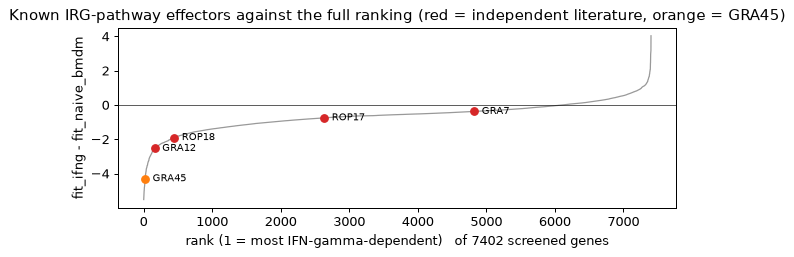

In [7]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.plot(screen['rank'].sort_values(), np.sort(screen['ifng_dependence']), lw=1, color='0.6')
for g, r in measured.iterrows():
    ax.plot(r['rank'], r['ifng_dependence'], 'o', ms=6,
            color='tab:red' if r.evidence_origin == 'literature' else 'tab:orange')
    ax.annotate(r['gene'], (r['rank'], r['ifng_dependence']), textcoords='offset points',
                xytext=(6, -2), fontsize=8)
ax.axhline(0, color='k', lw=0.5)
ax.set_xlabel('rank (1 = most IFN-gamma-dependent)   of %d screened genes' % n_screen)
ax.set_ylabel('fit_ifng - fit_naive_bmdm')
ax.set_title('Known IRG-pathway effectors against the full ranking (red = independent literature, orange = GRA45)')
fig.savefig(OUT / 'known_genes_rank_curve.png', dpi=150, bbox_inches='tight')
fig

## 6 · What else is at the top?

The 30 most IFN-gamma-dependent genes with everything we know about them. This is the artefact check: the expected biology is secreted effectors (dense granules, rhoptries, proteins with a signal peptide). If the top were instead full of ribosomal, apicoplast or mitochondrial genes, that would mean the contrast is tracking a growth-rate or scaling difference between the two conditions, not immune pressure.

In [8]:
top30 = ranking.head(30).join(nodes[['has_signal_peptide']]).copy()
top30['product'] = top30['product'].str.slice(0, 58)
top30 = top30[['product', 'ifng_dependence', 'percentile', 'fit_naive_bmdm', 'fit_ifng', 'fit_invitro_hff',
               'compartment', 'has_signal_peptide', 'host_facing', 'n_publications']]
top30.to_csv(OUT / 'top30.tsv', sep='\t')
top30.round(2)

,product,ifng_dependence,percentile,fit_naive_bmdm,fit_ifng,fit_invitro_hff,compartment,has_signal_peptide,host_facing,n_publications
gene_id,,,,,,,,,,
TGME49_269620,hypothetical protein,-5.51,0,1.54,-3.97,-0.34,NaN,0,<NA>,0
TGME49_313600,DDHD domain-containing protein,-5.45,0,2.88,-2.57,-1.04,NaN,0,<NA>,0
TGME49_237210,tyrosine kinase-like protein TKL4,-5.39,0,2.37,-3.02,-1.26,NaN,0,<NA>,1
TGME49_251440,"troponin c, isotype gamma, putative",-5.25,0,3.06,-2.19,-0.57,NaN,0,<NA>,0
TGME49_212770,inner membrane complex protein IMC34,-5.1,0,2.85,-2.25,-1.8,NaN,0,<NA>,1
TGME49_232800,hypothetical protein,-5.03,0,2.4,-2.63,-1.98,NaN,0,<NA>,0
TGME49_321530,cathepsin CPL,-5,0,1.73,-3.27,0.68,endomembrane vesicles,0,False,0
TGME49_295340,UV excision repair protein Rad23 protein,-4.99,0,1.44,-3.54,-0.37,NaN,0,<NA>,1
TGME49_312420,dense granule protein GRA38,-4.86,0,3.11,-1.75,-1.15,dense granules,0,False,3


In [9]:
top = ranking[ranking.percentile <= 0.05]
print('top 5%% of the ranking = %d genes' % len(top))
print('\nsignal peptide predicted:  top 5%%  %.1f%%   all screened  %.1f%%'
      % (100 * nodes.loc[top.index, 'has_signal_peptide'].mean(),
         100 * nodes.loc[ranking.index, 'has_signal_peptide'].mean()))
print('hyperLOPIT compartment known: top 5%% %d / %d' % (int(top.compartment.notna().sum()), len(top)))
print('\nhow many ribosomal proteins are in the top 5%%:', int(ribosomal.reindex(top.index).fillna(False).sum()),
      '(expected by chance: %.1f)' % (0.05 * ribosomal.reindex(ranking.index).fillna(False).sum()))
print('median ifng_dependence of ribosomal proteins: %.3f vs all screened %.3f'
      % (screen.loc[ribosomal.reindex(screen.index).fillna(False), 'ifng_dependence'].median(),
         screen['ifng_dependence'].median()))
top.compartment.value_counts().to_frame('genes in the top 5%').T

top 5% of the ranking = 370 genes

signal peptide predicted:  top 5%  10.0%   all screened  11.1%
hyperLOPIT compartment known: top 5% 34 / 370

how many ribosomal proteins are in the top 5%%: 0 (expected by chance: 7.0)
median ifng_dependence of ribosomal proteins: -0.531 vs all screened -0.563


compartment,nucleus,micronemes,dense granules,IMC,endomembrane vesicles,rhoptries,tubulin cytoskeleton,mitochondrion,plasma membrane,ER,Golgi,apicoplast,apical
genes in the top 5%,8,6,3,3,2,2,2,2,2,1,1,1,1


## 6b · Is the subtraction actually helping? A noise diagnostic

The top of the list has no effector signature -- hypothetical proteins, a splicing factor, a DNA-repair protein, an IMC protein, a troponin. That is worth taking seriously, because a difference of two noisy measurements has a known failure mode: it preferentially selects genes that happened to be extreme in *both* arms, in opposite directions. The next cell decomposes the top 30 to see whether that is what happened.

There is also a cheaper possibility worth testing. Both Wang columns are already normalised to a control, so `fit_ifng` **alone** is in principle "fitness in the activated macrophage relative to control" and may not need the naive arm subtracted at all. If the naive arm carries no signal of its own, subtracting it only adds its noise. So the same validation is run on three scores: the difference, `fit_ifng` alone, and `fit_naive_bmdm` alone (where the expected direction is the opposite -- positive, "better off in naive").

In [10]:
dec = ranking.head(30)[['fit_naive_bmdm', 'fit_ifng', 'ifng_dependence']]
print('top 30 of the difference: median fit_naive_bmdm %+.2f, median fit_ifng %+.2f'
      % (dec.fit_naive_bmdm.median(), dec.fit_ifng.median()))
print('all screened genes:       median fit_naive_bmdm %+.2f, median fit_ifng %+.2f'
      % (screen.fit_naive_bmdm.median(), screen.fit_ifng.median()))
print('of the top 30: %d have fit_naive_bmdm > 0 AND %d have fit_ifng < 0'
      % (int((dec.fit_naive_bmdm > 0).sum()), int((dec.fit_ifng < 0).sum())))
print('\nThe top of the difference is extreme in BOTH arms at once, in opposite directions -- the signature of')
print('a difference of noisy scores, not of a gene that is simply needed under IFN-gamma.')
dec.describe().loc[['mean', 'std', 'min', 'max']].round(2)

top 30 of the difference: median fit_naive_bmdm +1.99, median fit_ifng -2.64
all screened genes:       median fit_naive_bmdm +0.35, median fit_ifng -0.20
of the top 30: 30 have fit_naive_bmdm > 0 AND 30 have fit_ifng < 0

The top of the difference is extreme in BOTH arms at once, in opposite directions -- the signature of
a difference of noisy scores, not of a gene that is simply needed under IFN-gamma.


,fit_naive_bmdm,fit_ifng,ifng_dependence
mean,2,-2.62,-4.62
std,0.73,0.68,0.46
min,0.39,-3.97,-5.51
max,3.34,-0.91,-3.99


In [11]:
lit_ids = measured[measured.evidence_origin == 'literature'].index
cmp_rows = []
for name, col, direction in (('fit_ifng - fit_naive_bmdm (the contrast)', 'ifng_dependence', 'less'),
                             ('fit_ifng alone', 'fit_ifng', 'less'),
                             ('fit_naive_bmdm alone (expect the opposite sign)', 'fit_naive_bmdm', 'greater')):
    pos = screen.loc[lit_ids, col].values
    neg = screen.loc[~screen.index.isin(lit_ids), col].values
    u = stats.mannwhitneyu(pos, neg, alternative=direction)
    auc = u.statistic / (len(pos) * len(neg))
    if direction == 'less':
        auc = 1 - auc
    pct = screen[col].rank(pct=True) if direction == 'less' else 1 - screen[col].rank(pct=True)
    row = dict(score=name, expected_direction=direction, mannwhitney_p=u.pvalue, roc_auc=auc)
    for g in lit_ids:
        row[measured.loc[g, 'gene'] + '_pct'] = round(100 * float(pct[g]), 1)
    # in vivo agreement of the same score, for comparison
    both = screen[[col]].join(nodes['fit_invivo_brain']).dropna()
    row['brain_spearman'] = stats.spearmanr(both[col], both['fit_invivo_brain']).statistic
    cmp_rows.append(row)
cmp = pd.DataFrame(cmp_rows).set_index('score')
cmp.to_csv(OUT / 'score_comparison.tsv', sep='\t')
cmp.T.round(4)

score,fit_ifng - fit_naive_bmdm (the contrast),fit_ifng alone,fit_naive_bmdm alone (expect the opposite sign)
expected_direction,less,less,greater
mannwhitney_p,0.05736,0.01166,0.6702
roc_auc,0.7278,0.8274,0.4364
ROP18_pct,6,7.3,13.1
ROP17_pct,35.6,16.8,78.2
GRA7_pct,65.2,44.5,68.5
GRA12_pct,2.2,0.6,65.5
brain_spearman,0.1062,0.0528,-0.1179


**What the comparison says.** On the four independent known genes, `fit_ifng` **alone** scores better (rank-sum p about 0.012) than the contrast (about 0.057), while `fit_naive_bmdm` alone carries no signal at all (p about 0.67 in its own expected direction). The straightforward reading is that the naive arm contributes mostly noise here, because the Wang values are already control-normalised, so the second subtraction is not buying the specificity it is meant to buy.

**But the evidence is mixed, and it is not enough to decide.** The contrast agrees better with the in vivo mouse tissue rankings than `fit_ifng` alone (Spearman against brain roughly 0.11 against 0.05) and gives the stronger microneme enrichment, which argues the opposite way. And with four positives, p = 0.012 against p = 0.057 is not a real difference -- moving one gene a few hundred ranks would swap them.

**So this notebook reports the contrast as asked and registers it, and states that it is not demonstrated to be better than `fit_ifng` alone.** Choosing between them needs a real positive set -- the seven genes Wang validated individually, or an independent IFN-gamma-resistance list -- scored the instruction 70 way. That is the next step, and until it is done neither score should be deployed. Note also that comparing scores on the same small known set is already a use of that set for selection, so a scoreboard run must use positives that neither score has seen.

## 7 · Compartment enrichment

Formally: for each coarse hyperLOPIT compartment, a Fisher exact test (one-sided, greater) of "is in the top 5 % of the IFN-gamma-dependence ranking" against "has this compartment", among the screened genes that have a compartment at all. Counts are printed so the reader can see how thin each test is -- hyperLOPIT markers are only a few hundred of the screened genes, and several compartments have fewer than ten, where a single gene moves the p-value.

Benjamini-Hochberg q-values are reported across the compartments tested.

In [12]:
lab = ranking[ranking.compartment.notna()].copy()
lab['in_top'] = lab.percentile <= 0.05
rows = []
for comp, grp in lab.groupby('compartment'):
    a = int(grp.in_top.sum()); b = len(grp) - a
    c = int(lab.in_top.sum()) - a; d = len(lab) - len(grp) - c
    if len(grp) < 5:
        continue
    odds, p = stats.fisher_exact([[a, b], [c, d]], alternative='greater')
    rows.append(dict(compartment=comp, markers_screened=len(grp), in_top5pct=a,
                     expected=round(len(grp) * lab.in_top.mean(), 2),
                     other_compartments_in_top5pct=c, odds_ratio=odds, fisher_p=p))
enr = pd.DataFrame(rows).sort_values('fisher_p')
m = len(enr)
# Benjamini-Hochberg: step up from the LARGEST p-value, so the cumulative minimum runs backwards.
enr['bh_q'] = (enr.fisher_p * m / np.arange(1, m + 1))[::-1].cummin()[::-1].clip(upper=1)
enr.to_csv(OUT / 'compartment_enrichment.tsv', sep='\t', index=False)
print('%d compartments with >= 5 screened markers; %d markers screened in all, %d of them in the top 5%%'
      % (m, len(lab), int(lab.in_top.sum())))
enr.set_index('compartment').round(4)

17 compartments with >= 5 screened markers; 705 markers screened in all, 34 of them in the top 5%


,markers_screened,in_top5pct,expected,other_compartments_in_top5pct,odds_ratio,fisher_p,bh_q
compartment,,,,,,,
micronemes,28,6,1.35,28,6.321,0.0014,0.0238
tubulin cytoskeleton,8,2,0.39,32,6.927,0.0527,0.3939
nucleus,94,8,4.53,26,2.093,0.0695,0.3939
endomembrane vesicles,13,2,0.63,32,3.75,0.1263,0.5367
dense granules,37,3,1.78,31,1.813,0.2617,0.7798
IMC,38,3,1.83,31,1.758,0.2752,0.7798
Golgi,20,1,0.96,33,1.04,0.633,1
rhoptries,45,2,2.17,32,0.9128,0.6546,1
plasma membrane,64,2,3.09,32,0.6139,0.8341,1


## 8 · The in vivo cross-check (ranking only)

Giuliano 2024 screened the same kind of library in six mouse tissues. Those columns are a significance-weighted product, so they are used **only** as a ranking: Spearman correlation between the IFN-gamma-dependence rank and each tissue rank, over the genes measured in both. In both columns a more negative value means "more needed", so a **positive** Spearman means the two agree.

A caveat that limits what agreement can mean: both screens are in mice, both are affected by IFN-gamma in vivo, and Giuliano and Wang used overlapping library designs, so this is replication in a second system rather than independent confirmation. The honest reading is "the signal is not specific to one screen".

In [13]:
tissues = [c for c in nodes.columns if c.startswith('fit_invivo_')
           and 'hyperlopit_unassigned' not in c]
rows = []
for col in tissues:
    both = screen[['ifng_dependence']].join(nodes[col]).dropna()
    rho, p = stats.spearmanr(both['ifng_dependence'], both[col])
    topv = both[both.ifng_dependence <= both.ifng_dependence.quantile(0.05)][col]
    rows.append(dict(column=col, genes_in_common=len(both), spearman_rho=rho, p_value=p,
                     median_invivo_all=both[col].median(), median_invivo_top5pct_ifng=topv.median()))
agree = pd.DataFrame(rows).sort_values('spearman_rho', ascending=False)
agree.to_csv(OUT / 'invivo_agreement.tsv', sep='\t', index=False)
agree.set_index('column').round(4)

,genes_in_common,spearman_rho,p_value,median_invivo_all,median_invivo_top5pct_ifng
column,,,,,
fit_invivo_heart,7383,0.1092,0,-1.534,-3.493
fit_invivo_brain,7383,0.1062,0,-0.7099,-1.707
fit_invivo_lung,7383,0.069,0,-0.3577,-1.153
fit_invivo_spleen,7383,0.0656,0,-0.4812,-1.221
fit_invivo_liver,7383,0.0634,0,-0.188,-0.5696
fit_invivo_PE,7383,0.0375,0.0013,-0.0563,-0.2133
fit_invivo_young2019,115,-0.1176,0.2107,0.1316,0.2068


## 9 · The human comparison, stated honestly

The last column of the ranking is `fit_invitro_hff` -- Sidik 2016, human fibroblasts, absolute growth. It is reported **beside** the IFN-gamma dependence and never subtracted from it.

In [14]:
t = ranking.head(30)['fit_invitro_hff'].dropna()
print('of the top 30 IFN-gamma-dependent genes, %d have a human-fibroblast growth score' % len(t))
print('median fit_invitro_hff: top 30 %.2f   all screened genes %.2f'
      % (t.median(), ranking['fit_invitro_hff'].median()))
print('dispensable for growth in HFF (fit_invitro_hff > -1): %d / %d of the top 30, %.0f%% of all screened'
      % (int((t > -1).sum()), len(t), 100 * (ranking['fit_invitro_hff'] > -1).mean()))
known[['gene', 'ifng_dependence', 'rank', 'fit_invitro_hff']].round(2)

of the top 30 IFN-gamma-dependent genes, 29 have a human-fibroblast growth score
median fit_invitro_hff: top 30 -0.34   all screened genes -0.81
dispensable for growth in HFF (fit_invitro_hff > -1): 20 / 29 of the top 30, 52% of all screened


,gene,ifng_dependence,rank,fit_invitro_hff
gene_id,,,,
TGME49_205250,ROP18,-1.9,447,0.89
TGME49_258580,ROP17,-0.75,2635,1.29
TGME49_203310,GRA7,-0.38,4823,1.9
TGME49_288650,GRA12,-2.53,161,1.75
TGME49_308090,ROP5,NaN,NaN,NaN
TGME49_316250,GRA45,-4.3,21,1.15


**What this does and does not say.** The top IFN-gamma-dependent genes are, with few exceptions, dispensable for growth in human fibroblasts. The correct sentence is therefore:

> *needed under mouse immune pressure, but not needed for growth in human fibroblasts.*

That is **not** the same claim as "more important in mice than in humans". The two screens differ in two things at once -- host species and immune activation -- and they differ in a third, their scale. A human fibroblast is not an activated immune cell; a gene dispensable for growth in resting HFFs could still be essential in IFN-gamma-activated human macrophages, which use GBPs and ubiquitin-driven vacuole restriction rather than IRGs. ROP18 and GRA7, in fact, do have reported roles against human restriction.

**The measurement that would settle it** is the one we do not have: a genome-wide Toxoplasma CRISPR screen in **IFN-gamma-activated human macrophages** (or human fibroblasts) against the matching unactivated human cells -- the human twin of the Wang design, so that the human and mouse immune-dependence contrasts are each internally normalised and can be compared as two relative quantities. Only then is "mouse-specific" a measured statement rather than an inference from the absence of IRG genes in the human genome. Until it exists, the claim this notebook supports is the conditional one above.

## 10 · Registering the derived column in the information map

Instruction 72 says a new column is one `register(Trait(...))` line plus evidence rows. `ifng_dependence_mouse_macrophage` is a **tier 2 measurement** -- evidence a predictor may learn from, not a conclusion the map predicts. Its family is `crispr_macrophage` (held out together with the two Wang columns it is built from, otherwise it leaks them), its normalization is `relative_to_control` (the preferred class, since it is a within-study contrast against the unactivated condition) and its role is `measurement`.

The registration is executed here against the real registry, so the code below is known to run; `parascape/information_map.py` is **not edited by this notebook** (Einar reviews and commits).

In [15]:
from parascape import information_map as imap

trait = imap.register(imap.Trait(
    'ifng_dependence_mouse_macrophage', 'measure',
    'Fitness cost specific to IFN-gamma activation in mouse bone-marrow macrophages: '
    'fit_ifng - fit_naive_bmdm (Wang 2020, PMID 33067458). Negative = the gene is needed to survive the '
    'activated-macrophage attack. A within-study contrast only; never compared by subtraction with the human '
    'fibroblast or in vivo fitness columns, which are on different scales.',
    tier=2, family='crispr_macrophage', normalization='relative_to_control', role='measurement'))
print(trait)

evidence = [dict(gene_id=g, trait=trait.name, value=float(v), probability=imap.TIER_P['observed-screen'],
                 source_tier='observed-screen', reference='PMID:33067458',
                 dataset='wang2020_bmdm_crispr:fit_ifng-fit_naive_bmdm')
            for g, v in screen['ifng_dependence'].items()]
pd.DataFrame(evidence[:3])

Trait(name='ifng_dependence_mouse_macrophage', kind='measure', description='Fitness cost specific to IFN-gamma activation in mouse bone-marrow macrophages: fit_ifng - fit_naive_bmdm (Wang 2020, PMID 33067458). Negative = the gene is needed to survive the activated-macrophage attack. A within-study contrast only; never compared by subtraction with the human fibroblast or in vivo fitness columns, which are on different scales.', tier=2, family='crispr_macrophage', normalization='relative_to_control', role='measurement', depends_on=())


,gene_id,trait,value,probability,source_tier,reference,dataset
0,TGME49_313630,ifng_dependence_mouse_macrophage,-2.617,0.8,observed-screen,PMID:33067458,wang2020_bmdm_crispr:fit_ifng-fit_naive_bmdm
1,TGME49_209000,ifng_dependence_mouse_macrophage,-1.43,0.8,observed-screen,PMID:33067458,wang2020_bmdm_crispr:fit_ifng-fit_naive_bmdm
2,TGME49_225745,ifng_dependence_mouse_macrophage,-1.489,0.8,observed-screen,PMID:33067458,wang2020_bmdm_crispr:fit_ifng-fit_naive_bmdm


In [16]:
print('evidence rows ready for information_map.build():', len(evidence))
print('registry now holds', len(imap.TRAITS), 'traits;', sum(t.tier == 2 for t in imap.TRAITS.values()), 'tier-2')
print('\nline to add to parascape/information_map.py (for Einar to review and commit):')
print("""
        Trait('ifng_dependence_mouse_macrophage', 'measure',
              'IFN-gamma-specific fitness cost in mouse bone-marrow macrophages (fit_ifng - fit_naive_bmdm, '
              'Wang 2020 PMID 33067458); negative = needed to survive the activated macrophage. Within-study '
              'contrast; not comparable by subtraction with fit_invitro_hff or fit_invivo_*.',
              tier=2, family='crispr_macrophage', normalization='relative_to_control', role='measurement'),
""")

evidence rows ready for information_map.build(): 7402
registry now holds 6 traits; 1 tier-2

line to add to parascape/information_map.py (for Einar to review and commit):

        Trait('ifng_dependence_mouse_macrophage', 'measure',
              'IFN-gamma-specific fitness cost in mouse bone-marrow macrophages (fit_ifng - fit_naive_bmdm, '
              'Wang 2020 PMID 33067458); negative = needed to survive the activated macrophage. Within-study '
              'contrast; not comparable by subtraction with fit_invitro_hff or fit_invivo_*.',
              tier=2, family='crispr_macrophage', normalization='relative_to_control', role='measurement'),



## 11 · README for the result folder

In [17]:
def fmt(x, nd=3):
    return 'NA' if x is None or (isinstance(x, float) and not np.isfinite(x)) else f'{x:.{nd}f}'

lit = test.loc['literature only (independent)']
allp = test.loc['literature + GRA45']
known_lines = []
for g, r in known.iterrows():
    if not r.measured_in_screen:
        known_lines.append(f'| {r.gene} | {g} | not measured | — | — | {r.why_expected} |')
    else:
        known_lines.append(f'| {r.gene} | {g} | {fmt(r.ifng_dependence)} | {int(r["rank"])} of {n_screen} | '
                           f'top {fmt(r.percentile*100, 2)} % | {r.why_expected} |')
top_lines = [f'| {i+1} | {g} | {str(r["product"])[:60]} | {fmt(r.ifng_dependence)} | '
             f'{r.compartment if isinstance(r.compartment, str) else "—"} | {fmt(r.fit_invitro_hff, 2)} |'
             for i, (g, r) in enumerate(ranking.head(10).iterrows())]
enr_lines = [f'| {r.compartment} | {r.markers_screened} | {r.in_top5pct} | {r.expected} | '
             f'{fmt(r.odds_ratio, 2)} | {r.fisher_p:.2g} | {r.bh_q:.2g} |' for r in enr.itertuples()]
agr_lines = [f'| {r.column.replace("fit_invivo_", "")} | {r.genes_in_common} | {fmt(r.spearman_rho)} | '
             f'{r.p_value:.2g} |' for r in agree.itertuples()]

readme = f"""# Which Toxoplasma genes are specifically important under mouse immune pressure?

Built by `scripts/build_mouse_immune_dependence_notebook.py`; the executed notebook is
`notebooks/mouse_immune_dependence_2026_11_04.ipynb`. Asked by Einar 2026-11-04 as a first, concrete
inference target (easier than host-facing) **with a built-in score against known biology**.

## The question
A mouse macrophage activated by IFN-gamma attacks the parasitophorous vacuole with IRG GTPases. Mice have a
large IRG family; humans have essentially none. So: which Toxoplasma genes does the parasite need *only* when
the mouse macrophage is activated?

## The answer in one line
`ifng_dependence_mouse_macrophage = fit_ifng - fit_naive_bmdm` (Wang 2020, PMID 33067458), ranked over
{n_screen} genes measured in both conditions. Rank 1 = most IFN-gamma-dependent. Negative = the mutant loses
ground specifically when the macrophage is activated.

## Bottom line before the detail
The contrast is computable, is free of the scale artefact, and is **not strong enough to answer the question**.
GRA12 and ROP18 land near the top, ROP17 and GRA7 do not, the rank-sum p over the four independent known genes
is about 0.06, the top 30 contains almost no secreted effectors, and the one compartment that survives
multiple testing is micronemes rather than dense granules or rhoptries. The top of the difference is extreme in
both screen arms at once, which is how a difference of two noisy scores behaves, and `fit_ifng` alone scores
the known genes better than the difference does. Treat the ranking as a hypothesis list, not as an answer;
nothing was filled into the knowledge matrix.

## The scale trap, and how it was avoided
The fitness columns in `parascape/data/nodes.parquet` are **not on a common scale and must not be subtracted
across studies**. Re-verified in the notebook with the 158 ribosomal proteins (median, ribosomal vs all genes):

| column | study | ribosomal median | all genes | meaning |
|---|---|---|---|---|
| `fit_invitro_hff` | Sidik 2016, human fibroblasts | {fmt(scale.loc['fit_invitro_hff','ribosomal_median'],2)} | {fmt(scale.loc['fit_invitro_hff','all_genes_median'],2)} | absolute growth; negative = important |
| `fit_naive_bmdm` | Wang 2020, naive mouse BMDM | {fmt(scale.loc['fit_naive_bmdm','ribosomal_median'],2)} | {fmt(scale.loc['fit_naive_bmdm','all_genes_median'],2)} | growth already normalised out |
| `fit_ifng` | Wang 2020, IFN-gamma BMDM | {fmt(scale.loc['fit_ifng','ribosomal_median'],2)} | {fmt(scale.loc['fit_ifng','all_genes_median'],2)} | growth already normalised out |
| `fit_invivo_*` | Giuliano 2024, six mouse tissues | — | — | differential fitness x significance: a **ranking statistic**, not an effect size (GRA12 reads -41.56) |

Therefore the only subtraction performed anywhere in this analysis is **within Wang 2020** (same cells, same
library, same control-relative baseline). `fit_invitro_hff` is reported beside the result, never subtracted,
and `fit_invivo_*` is used only through Spearman rank correlation.

## Validation (a check, never a training set)
Positive set: the IRG-pathway effectors, mouse-specific because humans lack IRGs, plus GRA45 from the Wang
abstract itself (fetched from PubMed; `wang2020_pubmed_abstract.txt`). No threshold or parameter was chosen
using them.

| gene | ME49 id | ifng_dependence | rank | percentile | why expected |
|---|---|---|---|---|---|
{chr(10).join(known_lines)}

* ROP5 is **not measured** in the Wang screen, as expected: it is a tandem array of near-identical copies that
  a CRISPR library cannot target cleanly. That is a property of the technology, not a negative result.
* GRA45 comes from the same screen, so it is a positive control for the screen, not independent literature.

Test, independent literature genes only (n = {int(lit.n_positives)} measured, background {int(lit.n_background)}):
Mann-Whitney one-sided **p = {lit.mannwhitney_p:.2g}**, ROC-AUC **{fmt(lit.roc_auc)}**, median percentile
{fmt(lit.median_rank_percentile*100,2)} %; {int(lit['in_top_5pct'])} in the top 5 % (expected
{lit['expected_top_5pct']}, hypergeometric p = {lit['hypergeom_p_top_5pct']:.2g}),
{int(lit['in_top_1pct'])} in the top 1 % (expected {lit['expected_top_1pct']},
p = {lit['hypergeom_p_top_1pct']:.2g}).
With GRA45 added: p = {allp.mannwhitney_p:.2g}, AUC {fmt(allp.roc_auc)}.

**Read honestly: this is a weak, not a passing, result.** GRA12 (top 2 %) and ROP18 (top 6 %) land where the
biology says they should; ROP17 (36th percentile) and GRA7 (65th percentile) do not, and GRA7 sits in the
middle of the ranking, i.e. the contrast says nothing about it. The one-sided rank-sum p of about 0.06 is a
shift in the right direction that does **not** reach conventional significance. Adding GRA45 takes p below
0.02, but GRA45 was named by this very screen, so that is internal consistency, not recovery. With four
independent positives this cannot measure precision, and it is not a held-out benchmark in the instruction 70
sense -- it is a sanity score.

A likely reason GRA7 is flat is biological rather than technical: GRA7 is also needed for normal vacuole
architecture in unactivated cells, so it costs fitness in *both* Wang conditions and the subtraction cancels
it. A contrast can only see a gene whose requirement is conditional.

## Is the subtraction helping? (`score_comparison.tsv`)
The top of the difference is extreme in **both** arms at once, in opposite directions (top 30: median
`fit_naive_bmdm` {dec.fit_naive_bmdm.median():+.2f} and median `fit_ifng` {dec.fit_ifng.median():+.2f}, against
{screen.fit_naive_bmdm.median():+.2f} and {screen.fit_ifng.median():+.2f} for all screened genes; all 30 have
`fit_naive_bmdm` > 0 and `fit_ifng` < 0). That is the signature of a difference of two noisy scores, not of a
gene simply needed under IFN-gamma. Scoring three alternatives on the four known genes:

| score | rank-sum p | ROC-AUC | Spearman vs brain in vivo |
|---|---|---|---|
| `fit_ifng - fit_naive_bmdm` (the contrast) | {cmp.iloc[0].mannwhitney_p:.3f} | {fmt(cmp.iloc[0].roc_auc)} | {fmt(cmp.iloc[0].brain_spearman)} |
| `fit_ifng` alone | {cmp.iloc[1].mannwhitney_p:.3f} | {fmt(cmp.iloc[1].roc_auc)} | {fmt(cmp.iloc[1].brain_spearman)} |
| `fit_naive_bmdm` alone (opposite direction expected) | {cmp.iloc[2].mannwhitney_p:.3f} | {fmt(cmp.iloc[2].roc_auc)} | {fmt(cmp.iloc[2].brain_spearman)} |

Because both Wang columns are already control-normalised, `fit_ifng` alone is itself a relative quantity and
may not need the naive arm subtracted; on the known genes it scores better, and the naive arm alone carries no
signal in its own expected direction. **But the evidence is mixed**: the contrast agrees better with the in
vivo tissue rankings and gives the stronger compartment enrichment, and with four positives the difference
between p = 0.012 and p = 0.057 is not real. **Neither score is demonstrated to be better, and neither should
be deployed.** Deciding needs a genuine positive set -- the seven genes Wang validated individually, or an
independent IFN-gamma-resistance list -- scored the instruction 70 way with positives neither score has seen
(comparing scores on this small set is already a use of it for selection).

## The top of the ranking
| rank | gene | product | ifng_dependence | hyperLOPIT | fit_invitro_hff |
|---|---|---|---|---|---|
{chr(10).join(top_lines)}

**This top has no effector signature**, and that is the main negative result of the analysis: hypothetical
proteins, a splicing factor, a DNA-repair protein, an IMC protein, a troponin. Only GRA38 and GRA45 (rank 21)
are dense granule proteins. The expected answer -- a list dominated by secreted vacuole-facing effectors --
did not appear. See the next section for why.

Full table: `ranking.tsv`; the top 30 with signal peptide, host_facing and publication count: `top30.tsv`.
Artefact check: {int(ribosomal.reindex(top.index).fillna(False).sum())} ribosomal proteins in the top 5 %
(expected {0.05 * ribosomal.reindex(ranking.index).fillna(False).sum():.1f}), and the ribosomal median
ifng_dependence is {fmt(screen.loc[ribosomal.reindex(screen.index).fillna(False), 'ifng_dependence'].median())}
against {fmt(screen['ifng_dependence'].median())} for all screened genes -- no sign of a growth/scaling
artefact driving the top.

## Compartment enrichment (Fisher, one-sided, top 5 % vs the rest of the screened hyperLOPIT markers)
{len(lab)} screened genes carry a hyperLOPIT compartment; {int(lab.in_top.sum())} of them are in the top 5 %.

| compartment | markers screened | in top 5 % | expected | odds ratio | Fisher p | BH q |
|---|---|---|---|---|---|---|
{chr(10).join(enr_lines)}

**The expected enrichment is not the one that appears.** The prediction was dense granules and rhoptries --
the secreted effectors. What comes out instead is **micronemes** (the only compartment surviving multiple
testing), with dense granules and rhoptries near their expected counts (odds ratios around 1.8 and 0.9).
Micronemes are the invasion organelle, so an IFN-gamma-specific requirement for them is not an obvious
artefact -- a parasite that invades or egresses poorly spends longer exposed to an activated macrophage -- but
it is a hypothesis generated after the fact from 6 genes out of 28 markers, not a finding. The reassuring half
is negative: cytosol, ribosome, nucleolus and proteasome contribute **zero** genes to the top 5 %, and
apicoplast and mitochondrion are below expectation, so the top is not a growth or scaling artefact.

Caveat: hyperLOPIT has **no PVM class** -- the vacuole membrane is not a fraction in that experiment, so
"dense granules" and "rhoptries" are the only available proxies for vacuole-facing, and several compartments
have very few screened markers, where one gene moves the p-value. Only 705 of the 7402 screened genes carry a
compartment at all.

## In vivo agreement (ranking only)
| tissue | genes in common | Spearman rho | p |
|---|---|---|---|
{chr(10).join(agr_lines)}

Agreement is **real but very weak**: the strongest tissue (heart, brain) reaches Spearman rho of only about
0.11, which is highly significant only because 7,383 genes are being correlated. It means the contrast is not
pure noise; it does not mean the two screens measure the same thing. `fit_invivo_young2019` covers only 115
genes and is not interpretable here. Both screens are in mice and use overlapping library designs, so
agreement means "not specific to one screen", not independent confirmation.

## The human comparison, stated honestly
Of the top 30 IFN-gamma-dependent genes, {int((ranking.head(30)['fit_invitro_hff'] > -1).sum())} have
`fit_invitro_hff > -1`, i.e. they are dispensable for growth in human fibroblasts (median
{fmt(ranking.head(30)['fit_invitro_hff'].median(),2)} against {fmt(ranking['fit_invitro_hff'].median(),2)} for
all screened genes). The supported claim is **"needed under mouse immune pressure but not needed for growth in
human fibroblasts"**, which is *not* "more important in mice than in humans": the two screens differ in host
species, in immune activation and in scale all at once, and a resting fibroblast is not an activated immune
cell. The missing measurement is a genome-wide Toxoplasma CRISPR screen in **IFN-gamma-activated human
macrophages against matched unactivated human cells** -- the human twin of the Wang design -- so that the two
immune-dependence contrasts are each internally normalised and comparable.

## Every other caveat
* The contrast is a difference of two noisy screen scores, so its variance exceeds either column and its
  extremes are biased towards genes that were noisy in both arms; read single genes as a rank, not as an effect
  size, and do not quote a gene from the top 30 as "IFN-gamma-dependent" without an individual experiment.
* Wang reported 353 significant genes with their own statistics; `nodes.parquet` carries only the two fitness
  columns, so no per-gene significance or replicate variance is available here. Having the published FDR or
  the per-guide counts would let the contrast be tested properly instead of ranked raw, and is the first thing
  worth acquiring.
* Genes absent from the Wang library (poor guide coverage, tandem arrays like ROP5) are missing, not negative.
* IFN-gamma dependence measured in bone-marrow macrophages is one cell type of one mouse strain; it does not
  cover IRG-independent restriction, other cytokines, or other host cells.
* hyperLOPIT compartments cover only a few hundred of the screened genes, so compartment enrichment speaks
  about marker proteins, not about the whole top of the list.
* `host_facing` in the information map is a curated flag over 73 positives and 494 negatives; most of the
  ranking is simply empty there, and empty is not "no".
* Nothing here was filled into the information map. The derived column is registered as tier-2 evidence
  (`family='crispr_macrophage'`, `normalization='relative_to_control'`, `role='measurement'`) and the
  registration line is printed in the notebook for review; `parascape/information_map.py` was not edited.

## Files
| file | contents |
|---|---|
| `ranking.tsv` | all {n_screen} screened genes: product, ifng_dependence, rank, percentile, both Wang columns, fit_invitro_hff, compartment, host_facing, n_publications |
| `known_genes.tsv` | the validation set with ranks; the test result is appended as comment lines |
| `top30.tsv` | the 30 most IFN-gamma-dependent genes with signal peptide and host_facing |
| `compartment_enrichment.tsv` | Fisher test per coarse hyperLOPIT compartment |
| `score_comparison.tsv` | the contrast against `fit_ifng` alone and `fit_naive_bmdm` alone on the known genes |
| `invivo_agreement.tsv` | Spearman of the ranking against each mouse tissue column |
| `known_genes_rank_curve.png` | the positive set drawn on the full ranking |
| `wang2020_pubmed_abstract.txt` | the fetched abstract the GRA45 entry came from |
"""
(OUT / 'README.md').write_text(readme)
print(readme[:1500])
print('...\n\nREADME.md written:', len(readme), 'characters')

# Which Toxoplasma genes are specifically important under mouse immune pressure?

Built by `scripts/build_mouse_immune_dependence_notebook.py`; the executed notebook is
`notebooks/mouse_immune_dependence_2026_11_04.ipynb`. Asked by Einar 2026-11-04 as a first, concrete
inference target (easier than host-facing) **with a built-in score against known biology**.

## The question
A mouse macrophage activated by IFN-gamma attacks the parasitophorous vacuole with IRG GTPases. Mice have a
large IRG family; humans have essentially none. So: which Toxoplasma genes does the parasite need *only* when
the mouse macrophage is activated?

## The answer in one line
`ifng_dependence_mouse_macrophage = fit_ifng - fit_naive_bmdm` (Wang 2020, PMID 33067458), ranked over
7402 genes measured in both conditions. Rank 1 = most IFN-gamma-dependent. Negative = the mutant loses
ground specifically when the macrophage is activated.

## Bottom line before the detail
The contrast is computable, is free of the scal

## 12 · What was produced

Nothing was written into the knowledge matrix, no cell was filled, and `information_map.py` was not edited. The outputs are the ranking, the validation score, the two enrichment tables and the README.

In [18]:
for f in sorted(OUT.iterdir()):
    print(f'{f.name:38s} {f.stat().st_size:>9,d} bytes')

README.md                                 15,094 bytes
compartment_enrichment.tsv                 1,185 bytes
invivo_agreement.tsv                         748 bytes
known_genes.tsv                            2,015 bytes
known_genes_rank_curve.png                53,501 bytes
ranking.tsv                            1,023,831 bytes
score_comparison.tsv                         450 bytes
top30.tsv                                  4,288 bytes
wang2020_pubmed_abstract.txt               2,315 bytes
